In [1]:
# ===== P1 CELL 1: Connect Google Drive =====
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ===== P1 CELL 2: Load the three splits (fast, memory-efficient) =====
import os, json, time
import numpy as np
import pandas as pd

BASE = os.environ.get("BETH_BASE", "/content/drive/MyDrive/BETH_Triage")
RAW_DIR = os.path.join(BASE, "01_data_raw")
CACHE_DIR = os.path.join(BASE, "02_data_processed", "cache")
RES_DIR = os.path.join(BASE, "05_results")
FIG_DIR = os.path.join(BASE, "06_figures")
os.makedirs(CACHE_DIR, exist_ok=True)

with open(os.path.join(BASE, "config.json")) as fh:
    CONFIG = json.load(fh)
SEED = CONFIG["random_seed"]
np.random.seed(SEED)

SPLITS = {"train": "labelled_training_data.csv",
          "val":   "labelled_validation_data.csv",
          "test":  "labelled_testing_data.csv"}
DTYPES = {"timestamp": "float64", "processId": "int32", "threadId": "int32",
          "parentProcessId": "int32", "userId": "int32", "mountNamespace": "int64",
          "processName": "category", "hostName": "category", "eventId": "int32",
          "eventName": "category", "stackAddresses": "string", "argsNum": "int8",
          "returnValue": "int64", "args": "string", "sus": "int8", "evil": "int8"}

def load_split(name):
    cache = os.path.join(CACHE_DIR, f"{name}.pkl")
    if os.path.exists(cache):
        try:
            return pd.read_pickle(cache)
        except Exception as err:               # cache made by another pandas version
            print(f"  cache for {name} unreadable ({type(err).__name__}) - rebuilding from CSV")
    df = pd.read_csv(os.path.join(RAW_DIR, SPLITS[name]), dtype=DTYPES)
    df.insert(0, "row_id", np.arange(len(df), dtype=np.int64))   # permanent link to the source row
    df.to_pickle(cache)
    return df

data = {}
for name in SPLITS:
    t0 = time.time()
    data[name] = load_split(name)
    mb = data[name].memory_usage(deep=True).sum() / 1e6
    print(f"{name:5s}: {len(data[name]):>9,} rows, {data[name].shape[1]} columns, "
          f"{mb:,.0f} MB in memory, loaded in {time.time() - t0:.1f}s")

train:   763,144 rows, 17 columns, 253 MB in memory, loaded in 6.8s
val  :   188,967 rows, 17 columns, 59 MB in memory, loaded in 2.7s
test :   188,967 rows, 17 columns, 70 MB in memory, loaded in 1.7s


In [3]:
# ===== P1 CELL 3: Split overview - rows, hosts and labels =====
rows = []
for name, df in data.items():
    rows.append({
        "split": name,
        "rows": len(df),
        "hosts": df["hostName"].nunique(),
        "sus=1": int(df["sus"].sum()),
        "sus share %": round(100 * df["sus"].mean(), 2),
        "evil=1": int(df["evil"].sum()),
        "evil share %": round(100 * df["evil"].mean(), 2),
        "sus=1 but evil=0": int(((df["sus"] == 1) & (df["evil"] == 0)).sum()),
        "evil=1 but sus=0": int(((df["evil"] == 1) & (df["sus"] == 0)).sum()),
    })
overview = pd.DataFrame(rows)
overview.to_csv(os.path.join(RES_DIR, "P1_split_overview.csv"), index=False)
print(overview.to_string(index=False))
print("\nHosts per split:")
for name, df in data.items():
    print(f"  {name:5s}: {sorted(df['hostName'].astype(str).unique())}")

split   rows  hosts  sus=1  sus share %  evil=1  evil share %  sus=1 but evil=0  evil=1 but sus=0
train 763144      8   1269         0.17       0          0.00              1269                 0
  val 188967      4    786         0.42       0          0.00               786                 0
 test 188967      1 171459        90.73  158432         83.84             13027                 0

Hosts per split:
  train: ['ip-10-100-1-120', 'ip-10-100-1-173', 'ip-10-100-1-28', 'ip-10-100-1-34', 'ip-10-100-1-55', 'ip-10-100-1-57', 'ip-10-100-1-79', 'ubuntu']
  val  : ['ip-10-100-1-129', 'ip-10-100-1-165', 'ip-10-100-1-169', 'ubuntu']
  test : ['ip-10-100-1-217']


In [4]:
# ===== P1 CELL 4: Column profile - types, missing values, distinct values =====
prof = []
for col in data["train"].columns:
    if col == "row_id":
        continue
    entry = {"column": col, "dtype": str(data["train"][col].dtype)}
    for name, df in data.items():
        entry[f"missing_{name}"] = int(df[col].isna().sum())
        entry[f"distinct_{name}"] = int(df[col].nunique())
    entry["example (train)"] = str(data["train"][col].iloc[0])[:60]
    prof.append(entry)
profile = pd.DataFrame(prof)
profile.to_csv(os.path.join(RES_DIR, "P1_column_profile.csv"), index=False)
pd.set_option("display.width", 200)
print(profile.to_string(index=False))

tr = data["train"]
checks = {
    "eventId -> eventName is one-to-one (train)":
        bool(tr.groupby("eventId", observed=True)["eventName"].nunique().max() == 1
             and tr.groupby("eventName", observed=True)["eventId"].nunique().max() == 1),
    "mountNamespace distinct values (train)": int(tr["mountNamespace"].nunique()),
    "share of train rows with mountNamespace == 4026531840":
        round(float((tr["mountNamespace"] == 4026531840).mean()), 4),
    "share of train rows with empty stackAddresses '[]'":
        round(float((tr["stackAddresses"] == "[]").mean()), 4),
    "argsNum range (train)": f"{int(tr['argsNum'].min())} to {int(tr['argsNum'].max())}",
    "timestamp range (train, seconds since boot)":
        f"{tr['timestamp'].min():.1f} to {tr['timestamp'].max():.1f}",
}
print("\nStructural checks:")
for k, v in checks.items():
    print(f"  {k}: {v}")
with open(os.path.join(RES_DIR, "P1_structural_checks.json"), "w") as fh:
    json.dump(checks, fh, indent=2)

         column    dtype  missing_train  distinct_train  missing_val  distinct_val  missing_test  distinct_test                                              example (train)
      timestamp  float64              0          762911            0        188923             0         188967                                                  1809.495787
      processId    int32              0             545            0           190             0            198                                                          381
       threadId    int32              0             588            0           208             0            357                                                         7337
parentProcessId    int32              0             205            0            19             0             65                                                            1
         userId    int32              0               7            0             6             0              7                        

In [5]:
# ===== P1 CELL 5: Distribution shift between splits (labels NOT used) =====
tr = data["train"]
seen_proc = set(tr["processName"].astype(str))
seen_event = set(tr["eventName"].astype(str))
shift = []
for name, df in data.items():
    proc = df["processName"].astype(str)
    event = df["eventName"].astype(str)
    shift.append({
        "split": name,
        "processName values never seen in train": len(set(proc) - seen_proc),
        "rows with unseen processName %": round(100 * (~proc.isin(seen_proc)).mean(), 2),
        "eventName values never seen in train": len(set(event) - seen_event),
        "rows with unseen eventName %": round(100 * (~event.isin(seen_event)).mean(), 2),
        "rows with userId >= 1000 %": round(100 * (df["userId"] >= 1000).mean(), 2),
        "rows from OS processes (PID 0/1/2) %": round(100 * df["processId"].isin([0, 1, 2]).mean(), 2),
        "rows with negative returnValue %": round(100 * (df["returnValue"] < 0).mean(), 2),
    })
shift_df = pd.DataFrame(shift)
shift_df.to_csv(os.path.join(RES_DIR, "P1_distribution_shift.csv"), index=False)
print(shift_df.T.to_string(header=False))

split                                   train   val   test
processName values never seen in train      0     4    220
rows with unseen processName %            0.0  0.06  89.25
eventName values never seen in train        0     2     14
rows with unseen eventName %              0.0  0.01   0.06
rows with userId >= 1000 %               0.13  0.41  85.33
rows from OS processes (PID 0/1/2) %     2.14  2.42    1.1
rows with negative returnValue %         3.02  5.86  78.09


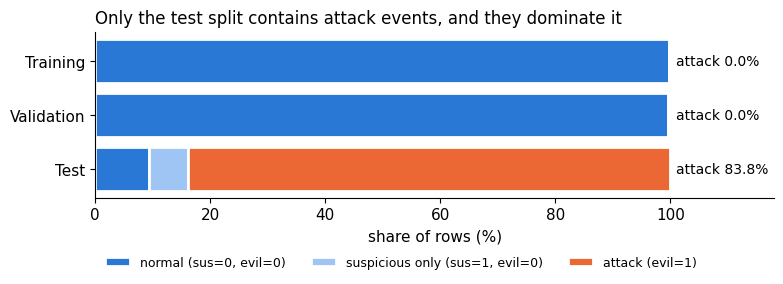

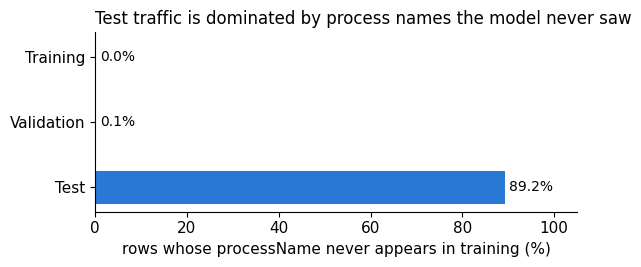

Saved figures to 06_figures/


In [6]:
# ===== P1 CELL 6: Two descriptive figures =====
import matplotlib.pyplot as plt

NORMAL_C, ATTACK_C, SUSONLY_C = "#2a78d6", "#eb6834", "#9ec5f4"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# Figure 1: what each split is made of
labels = ["Training", "Validation", "Test"]
normal = [100 * ((d["sus"] == 0) & (d["evil"] == 0)).mean() for d in data.values()]
susonly = [100 * ((d["sus"] == 1) & (d["evil"] == 0)).mean() for d in data.values()]
attack = [100 * (d["evil"] == 1).mean() for d in data.values()]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(labels, normal, color=NORMAL_C, label="normal (sus=0, evil=0)", edgecolor="white", linewidth=2)
ax.barh(labels, susonly, left=normal, color=SUSONLY_C, label="suspicious only (sus=1, evil=0)",
        edgecolor="white", linewidth=2)
ax.barh(labels, attack, left=[a + b for a, b in zip(normal, susonly)], color=ATTACK_C,
        label="attack (evil=1)", edgecolor="white", linewidth=2)
for i, a in enumerate(attack):
    ax.text(101, i, f"attack {a:.1f}%", va="center", fontsize=10)
ax.set_xlim(0, 118); ax.set_xlabel("share of rows (%)"); ax.invert_yaxis()
ax.set_title("Only the test split contains attack events, and they dominate it", loc="left", fontsize=12)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.28), ncol=3, frameon=False, fontsize=9)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG_DIR, f"P1_fig1_label_composition.{ext}"), dpi=300, bbox_inches="tight")
plt.show()

# Figure 2: how much of each split uses process names never seen in training
vals = shift_df.set_index("split")["rows with unseen processName %"].reindex(["train", "val", "test"])
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(labels, vals.values, color=NORMAL_C, height=0.5)
for i, v in enumerate(vals.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=10)
ax.set_xlim(0, 105); ax.set_xlabel("rows whose processName never appears in training (%)")
ax.invert_yaxis()
ax.set_title("Test traffic is dominated by process names the model never saw", loc="left", fontsize=12)
fig.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG_DIR, f"P1_fig2_unseen_process_names.{ext}"), dpi=300, bbox_inches="tight")
plt.show()
print("Saved figures to 06_figures/")